# Notebook 02 · Módulo 1: Detector de picos R

**Proyecto #7 · Detección de arritmias en tiempo real con TinyML**

El detector de picos R es la **base de todo el sistema**: si no encuentra bien los latidos, el clasificador de latidos, el detector de FA y las reglas de bradi/taqui fallan.

```
ECG → [Detector de picos R] ─┬─► recorta cada latido ──► Clasificador de latidos (notebook 03)
                             ├─► intervalos R–R ───────► Detector de FA (notebook 04)
                             └─► frecuencia (lpm) ─────► Reglas bradi/taqui (notebook 05)
```

Usamos el algoritmo clásico de **Pan y Tompkins (1985)**, simplificado y **causal** (solo usa el pasado, como en el Arduino).

| Lo que pide tu doctora | En este módulo |
|---|---|
| **Etiquetas** | Las posiciones de R anotadas en MIT-BIH |
| **Métricas** | **Sensibilidad** (cuántos latidos reales encontró) y **PPV** (cuántas detecciones eran latidos de verdad) |
| **Validación** | Los 44 registros de MIT-BIH sin marcapasos + **Noise Stress Test** (con ruido añadido) |

Aquí **no hay entrenamiento**: el algoritmo es una receta fija, así que no hace falta separar DS1/DS2 para este módulo.

In [1]:
%pip install -q wfdb numpy pandas scipy matplotlib seaborn scikit-learn

Note: you may need to restart the kernel to use updated packages.


In [2]:
from pathlib import Path
import shutil

if not Path("ecg_comun.py").exists():
    entradas = Path("/kaggle/input")
    encontrados = list(entradas.rglob("ecg_comun.py")) if entradas.exists() else []
    if not encontrados:
        raise FileNotFoundError("No encuentro ecg_comun.py: agrégalo con Add Input (el dataset donde lo subiste)")
    shutil.copy(encontrados[0], "ecg_comun.py")
    print("✓ ecg_comun.py copiado desde", encontrados[0])
else:
    print("✓ ecg_comun.py ya está junto al notebook")


✓ ecg_comun.py copiado desde /kaggle/input/datasets/lourdesgarcagarfias/cinc2017-proyecto7/cinc2017-proyecto7/ecg_comun.py


In [3]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy.signal import butter, find_peaks, sosfilt

import ecg_comun as ec

DATOS = Path("datos")
plt.rcParams["figure.figsize"] = (12, 3.5)
plt.rcParams["axes.grid"] = True

ec.descargar_base("mitdb", DATOS / "mitdb")
NST = [f"{b}e{snr}" for b in ("118", "119") for snr in ("24", "18", "12", "06", "00", "_6")]
ec.descargar_base("nstdb", DATOS / "nstdb", registros=NST)

Descargando mitdb en datos/mitdb (puede tardar varios minutos)...
Generating record list for: 100
Generating record list for: 101
Generating record list for: 102
Generating record list for: 103
Generating record list for: 104
Generating record list for: 105
Generating record list for: 106
Generating record list for: 107
Generating record list for: 108
Generating record list for: 109
Generating record list for: 111
Generating record list for: 112
Generating record list for: 113
Generating record list for: 114
Generating record list for: 115
Generating record list for: 116
Generating record list for: 117
Generating record list for: 118
Generating record list for: 119
Generating record list for: 121
Generating record list for: 122
Generating record list for: 123
Generating record list for: 124
Generating record list for: 200
Generating record list for: 201
Generating record list for: 202
Generating record list for: 203
Generating record list for: 205
Generating record list for: 207
Genera

## 1. El algoritmo paso a paso

Vamos a aplicar cada paso a 3 segundos del registro 100 y graficar qué le pasa a la señal.

| Paso | Qué hace | Por qué |
|---|---|---|
| 1. Pasabanda 5–15 Hz | Deja pasar sobre todo las frecuencias del QRS | Quita la deriva de línea base (lenta), las ondas P y T (lentas) y el ruido muscular (rápido) |
| 2. Derivada | Mide qué tan rápido cambia la señal | El QRS es la parte que cambia **más rápido** |
| 3. Cuadrado | Eleva al cuadrado | Todo queda positivo (no importa si el QRS va hacia arriba o abajo) y lo grande se hace mucho más grande |
| 4. Ventana móvil 150 ms | Promedia los últimos 150 ms | Junta la energía de cada QRS en una sola "loma" |
| 5. Umbral adaptativo | Una loma es latido si supera un umbral | El umbral se ajusta solo: sube si los latidos son grandes, baja si son pequeños |

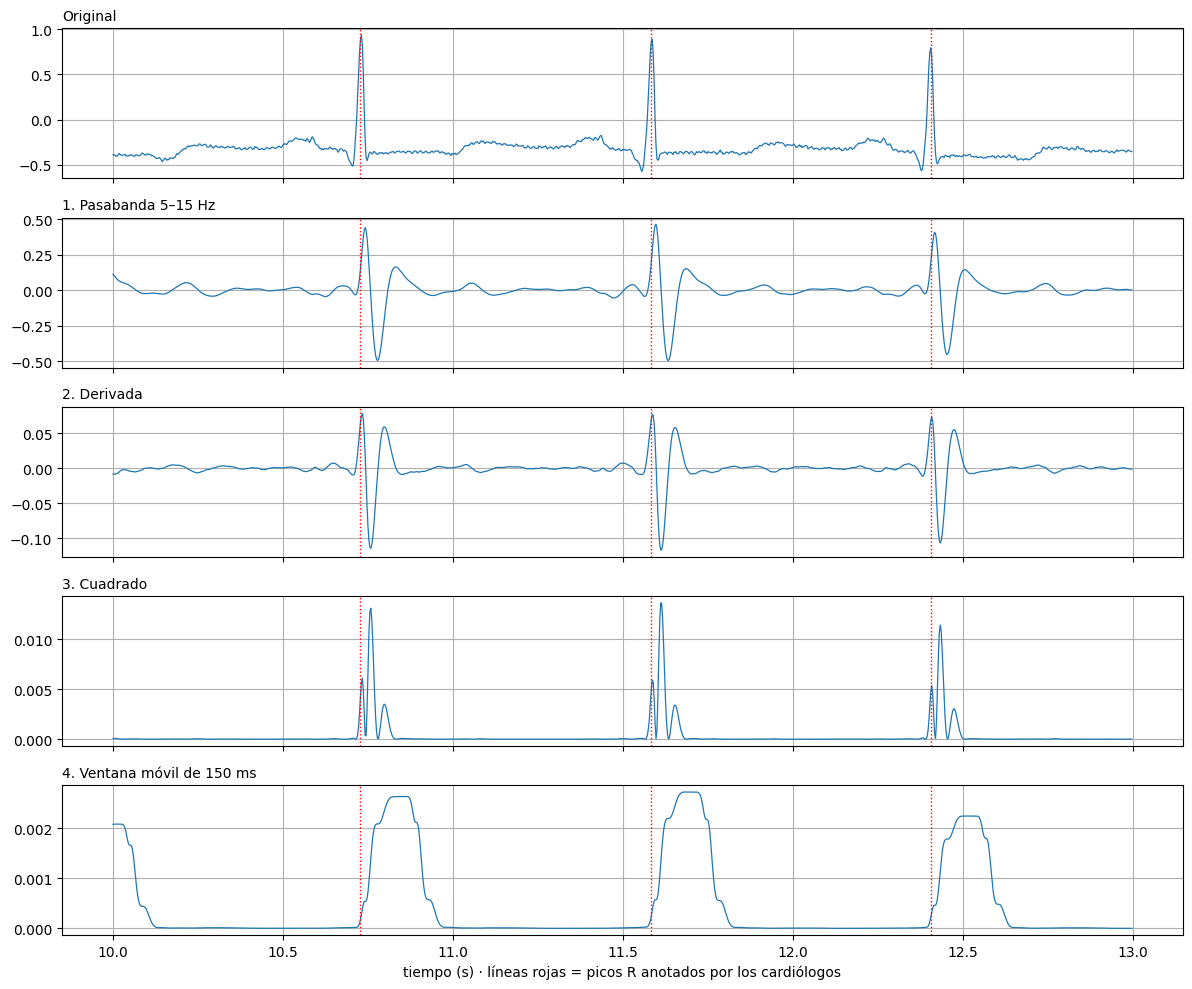

In [4]:
senal, fs, _ = ec.leer_senal(DATOS / "mitdb", "100")
latidos, simbolos = ec.leer_latidos(DATOS / "mitdb", "100")

# Los mismos pasos que hay dentro de ec.detectar_picos_r
sos = butter(2, [5, 15], btype="bandpass", fs=fs, output="sos")
banda = sosfilt(sos, senal)                                     # 1
derivada = np.diff(banda, prepend=banda[0])                     # 2
cuadrado = derivada ** 2                                        # 3
n = int(0.150 * fs)
integrada = np.convolve(cuadrado, np.ones(n) / n)[:len(cuadrado)]   # 4

a, b = int(10 * fs), int(13 * fs)
t = np.arange(a, b) / fs
pasos = [("Original", senal), ("1. Pasabanda 5–15 Hz", banda), ("2. Derivada", derivada),
         ("3. Cuadrado", cuadrado), ("4. Ventana móvil de 150 ms", integrada)]
fig, ax = plt.subplots(len(pasos), 1, figsize=(12, 10), sharex=True)
for eje, (nombre, x) in zip(ax, pasos):
    eje.plot(t, x[a:b], lw=0.9)
    for p in latidos[(latidos >= a) & (latidos < b)]:
        eje.axvline(p / fs, color="red", ls=":", lw=1)
    eje.set_title(nombre, loc="left", fontsize=10)
ax[-1].set_xlabel("tiempo (s) · líneas rojas = picos R anotados por los cardiólogos")
plt.tight_layout(); plt.show()

In [5]:
retrasos = []
for p in latidos:
    ventana = integrada[p: p + int(0.3 * fs)]
    if len(ventana):
        retrasos.append(1000 * np.argmax(ventana) / fs)
print(f"La loma llega en promedio {np.median(retrasos):.0f} ms después del pico R real")

La loma llega en promedio 119 ms después del pico R real


Este retraso importa para hipótesis de **< 200 ms por latido**: es parte de la **latencia algorítmica** (el tiempo que hay que esperar a que llegue la señal necesaria para decidir), que se suma al tiempo de cálculo del Arduino.

## 2. El detector completo en un registro

Ahora usamos la función completa `ec.detectar_picos_r`, que además tiene el **umbral adaptativo**, la **búsqueda hacia atrás** (si pasa mucho tiempo sin latido, busca otra vez con un umbral más bajo) y ubica el pico R exacto. Comparamos contra las anotaciones con una tolerancia de **±150 ms** (estándar ANSI/AAMI EC57).

Latidos anotados: 2273   Detectados: 2272
Verdaderos positivos: 2272   Se escaparon (FN): 1   Falsas detecciones (FP): 0
Sensibilidad: 99.96 %   PPV: 100.00 %
Diferencia típica entre el R detectado y el anotado: 5.6 ms


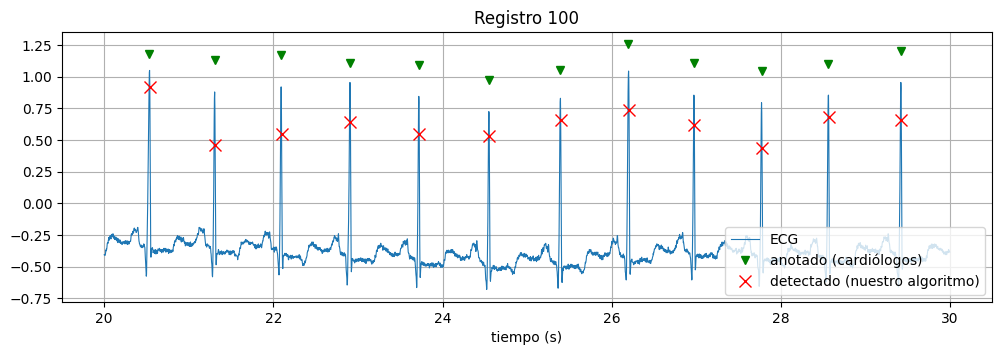

In [6]:
detectados = ec.detectar_picos_r(senal, fs)
res = ec.comparar_detecciones(latidos, detectados, fs)
print(f"Latidos anotados: {len(latidos)}   Detectados: {len(detectados)}")
print(f"Verdaderos positivos: {res['VP']}   Se escaparon (FN): {res['FN']}   Falsas detecciones (FP): {res['FP']}")
print(f"Sensibilidad: {100 * res['Se']:.2f} %   PPV: {100 * res['PPV']:.2f} %")
print(f"Diferencia típica entre el R detectado y el anotado: {np.median(res['desfase_ms']):.1f} ms")

a, b = int(20 * fs), int(30 * fs)
plt.figure()
plt.plot(np.arange(a, b) / fs, senal[a:b], lw=0.8, label="ECG")
anot = latidos[(latidos >= a) & (latidos < b)]
det = detectados[(detectados >= a) & (detectados < b)]
plt.plot(anot / fs, senal[anot] + 0.25, "gv", label="anotado (cardiólogos)")
plt.plot(det / fs, senal[det], "rx", ms=9, label="detectado (nuestro algoritmo)")
plt.legend(loc="lower right"); plt.xlabel("tiempo (s)"); plt.title("Registro 100")
plt.show()

## 3. Evaluación en todos los registros

Las dos métricas, con las palabras del notebook de seguros:

- **Sensibilidad (Se)** = VP / (VP + FN): de todos los latidos reales, ¿cuántos encontré? (los FN son latidos que **se escaparon**).
- **PPV** (valor predictivo positivo) = VP / (VP + FP): de todo lo que dije que era latido, ¿cuánto lo era de verdad? (los FP son **falsas alarmas**, por ejemplo una onda T grande o ruido).

Como referencia, Pan y Tompkins reportaron detectar el **99.3 %** de los QRS de MIT-BIH.

In [7]:
filas = []
for nombre in ec.listar_registros(DATOS / "mitdb"):
    if nombre in ec.CON_MARCAPASOS:
        continue
    x, fs_r, _ = ec.leer_senal(DATOS / "mitdb", nombre)
    ref, _ = ec.leer_latidos(DATOS / "mitdb", nombre)
    det = ec.detectar_picos_r(x, fs_r)
    r = ec.comparar_detecciones(ref, det, fs_r)
    filas.append({"registro": nombre, "latidos": len(ref), "VP": r["VP"], "FN": r["FN"], "FP": r["FP"],
                  "Se %": round(100 * r["Se"], 2), "PPV %": round(100 * r["PPV"], 2)})
tabla_det = pd.DataFrame(filas)

total = tabla_det[["latidos", "VP", "FN", "FP"]].sum()
print(f"TOTAL ({len(tabla_det)} registros): Se = {100 * total.VP / (total.VP + total.FN):.2f} %   "
      f"PPV = {100 * total.VP / (total.VP + total.FP):.2f} %")
print("\nLos 8 registros con más errores (FN + FP):")
display(tabla_det.assign(errores=tabla_det.FN + tabla_det.FP).sort_values("errores", ascending=False).head(8))

TOTAL (44 registros): Se = 99.58 %   PPV = 99.38 %

Los 8 registros con más errores (FN + FP):


,registro,latidos,VP,FN,FP,Se %,PPV %,errores
25,207,1860,1855,5,295,99.73,86.28,300
5,108,1763,1756,7,205,99.60,89.55,212
38,228,2053,1931,122,12,94.06,99.38,134
23,203,2980,2912,68,25,97.72,99.15,93
3,105,2572,2566,6,56,99.77,97.86,62
21,201,1963,1911,52,0,97.35,100.00,52
28,210,2650,2617,33,5,98.75,99.81,38
12,116,2412,2387,25,3,98.96,99.87,28


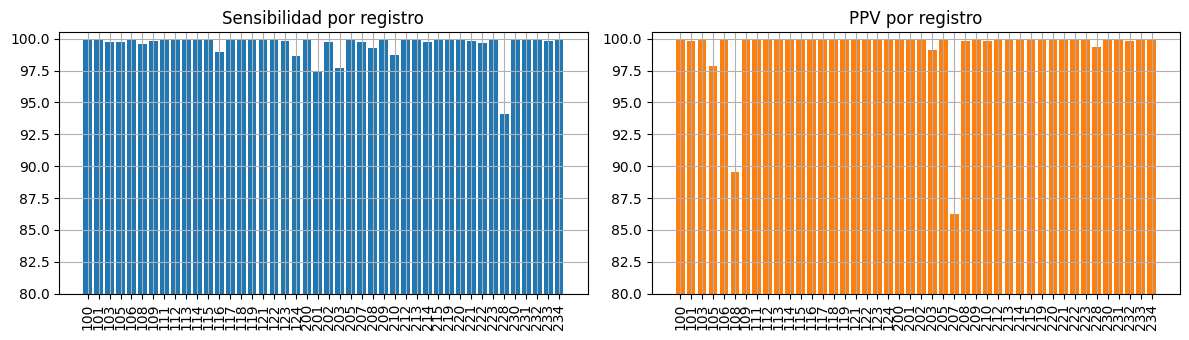

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
piso = min(80, tabla_det[["Se %", "PPV %"]].min().min() - 2)
ax[0].bar(tabla_det.registro, tabla_det["Se %"]); ax[0].set_ylim(piso, 100.5)
ax[0].set_title("Sensibilidad por registro"); ax[0].tick_params(axis="x", rotation=90)
ax[1].bar(tabla_det.registro, tabla_det["PPV %"], color="tab:orange"); ax[1].set_ylim(piso, 100.5)
ax[1].set_title("PPV por registro"); ax[1].tick_params(axis="x", rotation=90)
plt.tight_layout(); plt.show()

## 4. ¿Dónde se equivoca?

Mirar los errores enseña más que mirar el promedio. Graficamos 10 s del registro con más errores, alrededor del primer error.

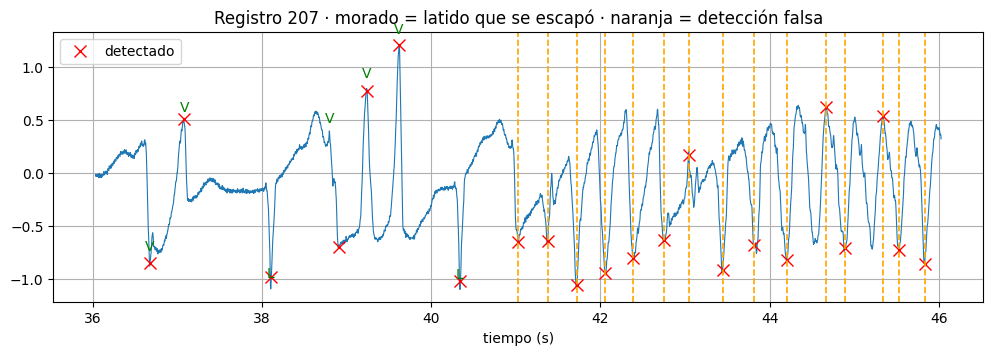

Registro 207: 5 latidos escapados y 295 detecciones falsas


In [9]:
peor = tabla_det.assign(errores=tabla_det.FN + tabla_det.FP).sort_values("errores").registro.iloc[-1]
x, fs_r, _ = ec.leer_senal(DATOS / "mitdb", peor)
ref, sim = ec.leer_latidos(DATOS / "mitdb", peor)
det = ec.detectar_picos_r(x, fs_r)
tol = int(0.15 * fs_r)
escapados = [p for p in ref if not np.any(np.abs(det - p) <= tol)]
falsos = [d for d in det if not np.any(np.abs(ref - d) <= tol)]
errores = sorted(escapados + falsos)
centro = errores[0] if errores else len(x) // 2
a, b = max(0, centro - 5 * fs_r), min(len(x), centro + 5 * fs_r)

plt.figure()
plt.plot(np.arange(a, b) / fs_r, x[a:b], lw=0.8)
for p, s in zip(ref, sim):
    if a <= p < b:
        plt.annotate(s, (p / fs_r, x[p]), xytext=(0, 8), textcoords="offset points", ha="center", color="green")
dd = det[(det >= a) & (det < b)]
plt.plot(dd / fs_r, x[dd], "rx", ms=9, label="detectado")
for p in escapados:
    if a <= p < b: plt.axvline(p / fs_r, color="purple", ls="--", lw=1.2)
for p in falsos:
    if a <= p < b: plt.axvline(p / fs_r, color="orange", ls="--", lw=1.2)
plt.title(f"Registro {peor} · morado = latido que se escapó · naranja = detección falsa")
plt.legend(); plt.xlabel("tiempo (s)"); plt.show()
print(f"Registro {peor}: {len(escapados)} latidos escapados y {len(falsos)} detecciones falsas")

**Cómo leerlo:** los errores típicos son (a) latidos muy **pequeños** o de **forma rara** (por ejemplo algunas V) que no superan el umbral, (b) **ondas T grandes** que parecen QRS y (c) tramos con mucho **ruido**.

## 5. Prueba de estrés con ruido (Noise Stress Test)

La base **Noise Stress Test** toma los registros 118 y 119 (limpios) y les añade **ruido real de electrodo en movimiento** a distintos niveles de **SNR** (relación señal/ruido): 24 dB es poco ruido y −6 dB es más ruido que señal. Es lo más parecido a una persona **moviéndose** con el AD8232 puesto. Las anotaciones son las mismas de los registros limpios.

,registro,base,SNR (dB),Se %,PPV %,FN,FP
0,118e24,118,24,100.00,99.96,0,1
1,118e18,118,18,100.00,99.96,0,1
2,118e12,118,12,99.78,95.71,5,102
3,118e06,118,6,98.86,79.41,26,584
4,118e00,118,0,94.42,71.53,127,856
5,118e_6,118,-6,57.86,59.53,960,896
6,119e24,119,24,100.00,99.95,0,1
7,119e18,119,18,100.00,99.95,0,1
8,119e12,119,12,100.00,93.51,0,138
9,119e06,119,6,99.45,74.99,11,659


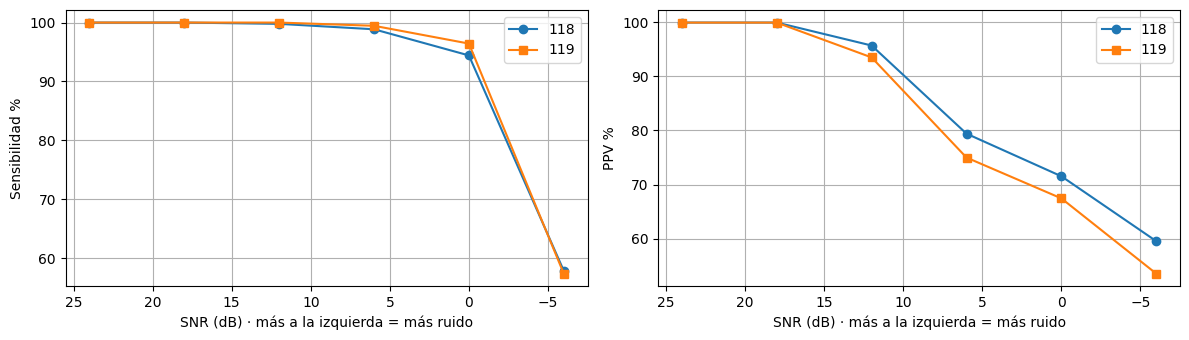

In [10]:
filas = []
for nombre in NST:
    x, fs_r, _ = ec.leer_senal(DATOS / "nstdb", nombre, canal=0)
    ref, _ = ec.leer_latidos(DATOS / "nstdb", nombre)
    det = ec.detectar_picos_r(x, fs_r)
    r = ec.comparar_detecciones(ref, det, fs_r)
    snr = int(nombre[4:].replace("_", "-"))
    filas.append({"registro": nombre, "base": nombre[:3], "SNR (dB)": snr,
                  "Se %": round(100 * r["Se"], 2), "PPV %": round(100 * r["PPV"], 2), "FN": r["FN"], "FP": r["FP"]})
tabla_ruido = pd.DataFrame(filas)
display(tabla_ruido)

fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
for base, m in [("118", "o-"), ("119", "s-")]:
    d = tabla_ruido[tabla_ruido.base == base].sort_values("SNR (dB)")
    ax[0].plot(d["SNR (dB)"], d["Se %"], m, label=base)
    ax[1].plot(d["SNR (dB)"], d["PPV %"], m, label=base)
for eje, nom in zip(ax, ["Sensibilidad %", "PPV %"]):
    eje.set_xlabel("SNR (dB) · más a la izquierda = más ruido"); eje.set_ylabel(nom); eje.legend()
    eje.invert_xaxis()
plt.tight_layout(); plt.show()

**Cómo leerlo:** con poco ruido (24 dB) el detector debe funcionar casi igual que en los registros limpios. Conforme baja el SNR, normalmente **cae el PPV primero** (el ruido produce detecciones falsas), y eso después se convierte en **falsas alarmas** de taquicardia o de FA. Esto justifica que en el notebook 05 decidamos **cómo tratar los artefactos**.

---
